# BINGUNG-ID · Pelatihan model & analisis

Notebook ini memakai `data/dataset_berlabel.csv` (hasil `kappa --putusan`) dan `data/komentar_bersih.csv`.
Semua tabel dan gambar disimpan ke folder **`hasil/`** di Drive.

**Sebelum mulai:** menu **Runtime → Change runtime type → T4 GPU**, lalu **Runtime → Run all**.
Total waktu sekitar 15–20 menit; bagian IndoBERT paling lama.

| Sel | Isi |
|---|---|
| 3 | Sebaran label, kappa |
| 4 | Pembagian data per video |
| 5–6 | TF-IDF (NB, LR, SVM) dan IndoBERT / IndoBERTweet |
| 7–8 | Tabel hasil, matriks kebingungan, contoh salah klasifikasi |
| 9 | Jenis kebingungan per mapel |
| 10 | Indeks Kebingungan per topik & posisi dalam video |
| 11 | Ringkasan angka |
| 12 | Simpan model + fungsi prediksi CSV |

In [ ]:
# Sel 1 · Folder kerja
import os
FOLDER = "/content/drive/MyDrive/DIMAS_TI_2026"# ganti bila folder kalian berbeda
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:                              # dijalankan di luar Colab
    FOLDER = os.environ.get("BINGUNG_FOLDER", os.getcwd())
os.chdir(FOLDER)
os.makedirs("hasil", exist_ok=True)
print("Folder kerja:", os.getcwd())
print("Isi data/:", sorted(os.listdir("data")))

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/DIMAS_TI_2026
Isi data/: ['cadangan_anotasi_Rani_700baris.xlsx', 'dataset_berlabel.csv', 'ketidaksepakatan.csv', 'ketidaksepakatan.gsheet', 'komentar_bersih.csv', 'komentar_bersih.gsheet', 'komentar_mentah.csv', 'laporan_kappa.txt', 'log_ambil.csv', 'mentah', 'ringkasan_dataset.csv', 'sampel_anotasi.csv', 'video_meta.csv']


In [ ]:
# Sel 2 · Pustaka & pengaturan
import re, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore", category=FutureWarning)
try:
    display
except NameError:
    display = print

SEED = 2026
LABEL = ["BINGUNG", "KOREKSI", "PAHAM", "LAIN"]
JENIS = ["KONSEPTUAL", "PROSEDURAL", "NOTASI", "UMUM"]
MAPEL = ["Matematika", "Fisika", "Kimia", "Biologi"]
WARNA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # palet kategorikal tervalidasi, aman buta warna
BIRU, TINTA, TINTA2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"


def set_seed(s=SEED):
    random.seed(s)
    np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s)
        torch.cuda.manual_seed_all(s)
    except ImportError:
        pass


set_seed()
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 10.5, "font.family": "DejaVu Sans",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": TINTA2,
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "grid.color": GRID, "grid.linewidth": 0.8,
})


def simpan_gambar(fig, nama):
    fig.savefig(f"hasil/{nama}.png", bbox_inches="tight", facecolor="white")
    print(f"-> hasil/{nama}.png")

In [ ]:
# Sel 3 · Muat dataset berlabel
data = pd.read_csv("data/dataset_berlabel.csv", dtype=str).fillna("")
n_awal = len(data)
data = data[data["label"].isin(LABEL)].reset_index(drop=True)
print(f"{len(data)} komentar dipakai (dibuang {n_awal - len(data)}: label kosong atau masih PERLU_DISKUSI)")
assert data["video_id"].ne("").all(), "video_id kosong: pakai dataset_berlabel.csv buatan bingung_scraper.py"
if "topik" not in data or data["topik"].eq("").all():
    data["topik"] = data["judul"]
data["topik"] = data["topik"].where(data["topik"] != "", data["judul"])


def bersih_tfidf(t):
    t = t.lower().replace("<url>", " url ").replace("@pengguna", " pengguna ")
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)          # "bingunggg" -> "bingungg", "???" -> "??"
    t = re.sub(r"\d+(?:[.,]\d+)?", " 0 ", t)        # angka diseragamkan
    return re.sub(r"\s+", " ", t).strip()


def bersih_transformer(t):        # kedua model IndoBERT bersifat uncased
    return t.replace("<URL>", "httpurl").replace("@pengguna", "@user").lower()


data["teks_model"] = data["teks_bersih"].map(bersih_tfidf)

tabel_label = pd.crosstab(data["mapel"], data["label"], margins=True, margins_name="Total")
tabel_label = tabel_label.reindex(columns=LABEL + ["Total"], fill_value=0)
tabel_label = tabel_label.reindex([m for m in MAPEL if m in tabel_label.index] + ["Total"])
tabel_label.to_csv("hasil/tabel_sebaran_label.csv")
print("\nSebaran label per mapel (-> hasil/tabel_sebaran_label.csv)")
display(tabel_label)
if "sumber_label" in data:
    print("Sumber label:", data["sumber_label"].value_counts().to_dict())
print("Video:", data["video_id"].nunique(), "| rata-rata kata per komentar:",
      round(data["teks_bersih"].str.split().str.len().mean(), 1))
if os.path.exists("data/laporan_kappa.txt"):
    print("\n" + open("data/laporan_kappa.txt", encoding="utf-8").read())

1498 komentar dipakai (dibuang 2: label kosong atau masih PERLU_DISKUSI)

Sebaran label per mapel (-> hasil/tabel_sebaran_label.csv)


label,BINGUNG,KOREKSI,PAHAM,LAIN,Total
mapel,,,,,
Matematika,117,31,85,141,374
Fisika,121,12,95,147,375
Kimia,159,9,129,78,375
Biologi,130,4,84,156,374
Total,527,56,393,522,1498


Sumber label: {'ai_diverifikasi': 1200, 'manusia_irisan': 298}
Video: 241 | rata-rata kata per komentar: 13.0

LAPORAN KESEPAKATAN ANTAR-ANOTATOR · BINGUNG-ID

Komentar irisan yang dinilai >=2 anotator: 300
  Cohen's kappa Budi vs Rani: 0.871 (hampir sempurna) · kesepakatan mentah 91.3% · n=300
  Cohen's kappa Budi vs Sari: 0.822 (hampir sempurna) · kesepakatan mentah 88.0% · n=300
  Cohen's kappa Rani vs Sari: 0.862 (hampir sempurna) · kesepakatan mentah 90.7% · n=300
  Rata-rata Cohen's kappa: 0.852 (hampir sempurna)
  Fleiss' kappa (3 anotator, n=300): 0.852 (hampir sempurna)
  Label yang paling sering tertukar: LAIN vs PAHAM (12), BINGUNG vs LAIN (11), BINGUNG vs PAHAM (8), BINGUNG vs KOREKSI (7)

VERIFIKASI LABEL AI (lembar tahap 2)
  Diperiksa: 1200 komentar | label diubah: 5 (0.4%) | jenis BINGUNG diubah: 0
  Usulan AI RAGU: 146 komentar, 3.4% labelnya diubah
  Usulan AI YAKIN: 1054 komentar, 0.0% labelnya diubah
  Perubahan terbanyak: LAIN->PAHAM (3), LAIN->BINGUNG (1), KOREKSI

In [ ]:
# Sel 4 · Pembagian data PER VIDEO: komentar dari satu video tidak pernah ada di latih dan uji sekaligus
y = data["label"].map(LABEL.index).to_numpy()
grup = data["video_id"].to_numpy()
idx_latih_penuh, idx_uji = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(data, y, grup))
sub_l, sub_v = next(StratifiedGroupKFold(8, shuffle=True, random_state=SEED)
                    .split(idx_latih_penuh, y[idx_latih_penuh], grup[idx_latih_penuh]))
idx_latih, idx_val = idx_latih_penuh[sub_l], idx_latih_penuh[sub_v]
assert not set(grup[idx_uji]) & set(grup[idx_latih_penuh]), "kebocoran video latih-uji"
assert not set(grup[idx_val]) & set(grup[idx_latih]), "kebocoran video latih-validasi"
LIPATAN_CV = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(data, y, grup))

bagi = pd.DataFrame({n: pd.Series(data["label"].to_numpy()[ix]).value_counts().reindex(LABEL, fill_value=0)
                     for n, ix in [("latih", idx_latih), ("validasi", idx_val), ("uji", idx_uji)]}).T
bagi["total"] = bagi.sum(axis=1)
bagi["video"] = [len(set(grup[ix])) for ix in (idx_latih, idx_val, idx_uji)]
bagi.to_csv("hasil/tabel_pembagian_data.csv")
print("Pembagian data (-> hasil/tabel_pembagian_data.csv)")
display(bagi)

Pembagian data (-> hasil/tabel_pembagian_data.csv)


,BINGUNG,KOREKSI,PAHAM,LAIN,total,video
latih,376,40,286,364,1066,168
validasi,48,5,34,75,162,25
uji,103,11,73,83,270,48


In [ ]:
# Sel 5 · Model dasar TF-IDF: hiperparameter dipilih di validasi, lalu dilatih ulang di latih+validasi
def fitur_tfidf():
    return FeatureUnion([
        ("kata", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("huruf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ])


KANDIDAT = {
    "Mayoritas (acuan bawah)": ([None], lambda c: DummyClassifier(strategy="most_frequent")),
    "TF-IDF + Naive Bayes": ([0.1, 0.3, 1.0], lambda c: ComplementNB(alpha=c)),
    "TF-IDF + Regresi Logistik": ([1, 3, 10], lambda c: LogisticRegression(C=c, class_weight="balanced", max_iter=3000)),
    "TF-IDF + SVM linear": ([0.1, 0.3, 1.0], lambda c: LinearSVC(C=c, class_weight="balanced")),
}
X = data["teks_model"].to_numpy()
hasil_model, prediksi_uji, pipa_tfidf = [], {}, {}


def baris_hasil(nama, pred, keterangan, hiper=""):
    f1k = f1_score(y[idx_uji], pred, average=None, labels=range(len(LABEL)), zero_division=0)
    return {"model": nama, "hiperparameter": hiper,
            "macro_F1_uji": round(f1_score(y[idx_uji], pred, average="macro"), 3),
            "akurasi_uji": round(accuracy_score(y[idx_uji], pred), 3),
            **{f"F1_{l}": round(v, 3) for l, v in zip(LABEL, f1k)}, "keterangan": keterangan}


for nama, (grid, buat) in KANDIDAT.items():
    skor = {c: f1_score(y[idx_val], Pipeline([("fitur", fitur_tfidf()), ("clf", buat(c))])
                        .fit(X[idx_latih], y[idx_latih]).predict(X[idx_val]), average="macro") for c in grid}
    c_pilih = max(skor, key=skor.get)
    pipa = Pipeline([("fitur", fitur_tfidf()), ("clf", buat(c_pilih))])
    cv = cross_validate(pipa, X, y, cv=LIPATAN_CV, scoring="f1_macro")["test_score"]
    pipa.fit(X[idx_latih_penuh], y[idx_latih_penuh])
    pipa_tfidf[nama] = (pipa, cv.mean())
    prediksi_uji[nama] = pipa.predict(X[idx_uji])
    hasil_model.append(baris_hasil(nama, prediksi_uji[nama], f"CV 5-lipatan per video: {cv.mean():.3f} ± {cv.std():.3f}",
                                   "" if c_pilih is None else f"C/alpha = {c_pilih}"))
    print(f"{nama:28s} macro-F1 uji {hasil_model[-1]['macro_F1_uji']:.3f} | CV {cv.mean():.3f} ± {cv.std():.3f}")

NAMA_TFIDF_TERBAIK = max((n for n in pipa_tfidf if not n.startswith("Mayoritas")), key=lambda n: pipa_tfidf[n][1])
print("\nTF-IDF terbaik (dipilih dari CV, bukan dari data uji):", NAMA_TFIDF_TERBAIK)

Mayoritas (acuan bawah)      macro-F1 uji 0.118 | CV 0.122 ± 0.006
TF-IDF + Naive Bayes         macro-F1 uji 0.566 | CV 0.573 ± 0.024
TF-IDF + Regresi Logistik    macro-F1 uji 0.732 | CV 0.724 ± 0.017
TF-IDF + SVM linear          macro-F1 uji 0.721 | CV 0.700 ± 0.018

TF-IDF terbaik (dipilih dari CV, bukan dari data uji): TF-IDF + Regresi Logistik


In [ ]:
# Sel 6 · Fine-tuning IndoBERT dan IndoBERTweet (butuh GPU; ±10 menit untuk 2 model × 3 benih)
JALANKAN_TRANSFORMER = True
MODEL_TRANSFORMER = {
    "IndoBERT-base (p1)": "indobenchmark/indobert-base-p1",
    "IndoBERTweet": "indolem/indobertweet-base-uncased",
}
BENIH = [2026, 2027, 2028]          # kurangi jadi [2026] bila waktu sangat mepet
EPOCH, LR, BS, MAKS_TOKEN = 5, 3e-5, 16, 128

model_tr, tok_tr, nama_tr_terbaik, val_tr_terbaik = None, None, None, -1.0
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    PERANGKAT = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    PERANGKAT = None
if PERANGKAT != "cuda":
    print("! GPU tidak aktif: bagian IndoBERT dilewati. Aktifkan Runtime > Change runtime type > T4 GPU, "
          "lalu Run all lagi. Hasil TF-IDF tetap bisa dipakai.")
    JALANKAN_TRANSFORMER = JALANKAN_TRANSFORMER and PERANGKAT == "cpu" and os.environ.get("BINGUNG_UJI_CPU") == "1"

TEKS_TR = data["teks_bersih"].map(bersih_transformer).tolist()


def prob_teks(model, tok, daftar_teks, bs=64):
    model.eval()
    keluar = []
    with torch.no_grad():
        for i in range(0, len(daftar_teks), bs):
            enc = tok(daftar_teks[i:i + bs], truncation=True, max_length=MAKS_TOKEN, padding=True, return_tensors="pt")
            enc = {k: v.to(PERANGKAT) for k, v in enc.items()}
            keluar.append(torch.softmax(model(**enc).logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(keluar) if keluar else np.zeros((0, len(LABEL)))


def latih_transformer(nama_hf, benih):
    set_seed(benih)
    tok = AutoTokenizer.from_pretrained(nama_hf)
    model = AutoModelForSequenceClassification.from_pretrained(nama_hf, num_labels=len(LABEL)).to(PERANGKAT)
    bobot = compute_class_weight("balanced", classes=np.arange(len(LABEL)), y=y[idx_latih])
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(bobot, dtype=torch.float, device=PERANGKAT))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = EPOCH * math.ceil(len(idx_latih) / BS)
    jadwal = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    teks_val = [TEKS_TR[i] for i in idx_val]
    terbaik, keadaan, riwayat = -1.0, None, []
    for ep in range(EPOCH):
        model.train()
        urut = np.random.RandomState(benih * 100 + ep).permutation(idx_latih)
        for i in range(0, len(urut), BS):
            b = urut[i:i + BS]
            enc = tok([TEKS_TR[j] for j in b], truncation=True, max_length=MAKS_TOKEN, padding=True, return_tensors="pt")
            enc = {k: v.to(PERANGKAT) for k, v in enc.items()}
            loss = loss_fn(model(**enc).logits, torch.tensor(y[b], device=PERANGKAT))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); jadwal.step(); opt.zero_grad()
        f1v = f1_score(y[idx_val], prob_teks(model, tok, teks_val).argmax(1), average="macro")
        riwayat.append(round(f1v, 3))
        if f1v > terbaik:
            terbaik = f1v
            keadaan = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(keadaan)
    return model, tok, terbaik, riwayat


if JALANKAN_TRANSFORMER:
    teks_uji = [TEKS_TR[i] for i in idx_uji]
    for nama, nama_hf in MODEL_TRANSFORMER.items():
        pred_semua, f1_semua = [], []
        for benih in BENIH:
            try:
                model, tok, f1v, riwayat = latih_transformer(nama_hf, benih)
            except Exception as e:                  # mis. gagal unduh model: lanjut ke model berikutnya
                print(f"! {nama} gagal dilatih ({type(e).__name__}: {str(e)[:200]}). Dilewati.")
                break
            pred = prob_teks(model, tok, teks_uji).argmax(1)
            pred_semua.append(pred)
            f1_semua.append(f1_score(y[idx_uji], pred, average="macro"))
            print(f"{nama} · benih {benih}: F1 validasi per epoch {riwayat} -> macro-F1 uji {f1_semua[-1]:.3f}")
            if f1v > val_tr_terbaik:                  # simpan model dengan F1 VALIDASI terbaik untuk pemetaan
                if model_tr is not None:
                    del model_tr
                model_tr, tok_tr, nama_tr_terbaik, val_tr_terbaik = model, tok, nama, f1v
                pred_model_tr = pred
            else:
                del model
            torch.cuda.empty_cache()
        if not f1_semua:
            continue
        wakil = int(np.argsort(f1_semua)[len(f1_semua) // 2])   # benih dengan skor median sebagai wakil
        prediksi_uji[nama] = pred_semua[wakil]
        baris = baris_hasil(nama, pred_semua[wakil], f"rata-rata {len(f1_semua)} benih: "
                            f"{np.mean(f1_semua):.3f} ± {np.std(f1_semua):.3f}", f"lr {LR}, {EPOCH} epoch, batch {BS}")
        baris["macro_F1_uji"] = round(float(np.mean(f1_semua)), 3)
        hasil_model.append(baris)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

... (30 outputs left out)

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


IndoBERTweet · benih 2028: F1 validasi per epoch [0.534, 0.575, 0.58, 0.595, 0.593] -> macro-F1 uji 0.755


Hasil pada data uji (video yang tidak pernah dilihat saat latih) -> hasil/tabel_hasil_model.csv


,model,hiperparameter,macro_F1_uji,akurasi_uji,F1_BINGUNG,F1_KOREKSI,F1_PAHAM,F1_LAIN,keterangan
4,IndoBERT-base (p1),"lr 3e-05, 5 epoch, batch 16",0.774,0.826,0.864,0.588,0.865,0.761,rata-rata 3 benih: 0.774 ± 0.010
5,IndoBERTweet,"lr 3e-05, 5 epoch, batch 16",0.746,0.822,0.854,0.455,0.863,0.795,rata-rata 3 benih: 0.746 ± 0.006
2,TF-IDF + Regresi Logistik,C/alpha = 3,0.732,0.793,0.817,0.533,0.853,0.726,CV 5-lipatan per video: 0.724 ± 0.017
3,TF-IDF + SVM linear,C/alpha = 0.3,0.721,0.789,0.818,0.500,0.861,0.706,CV 5-lipatan per video: 0.700 ± 0.018
1,TF-IDF + Naive Bayes,C/alpha = 0.1,0.566,0.715,0.784,0.125,0.802,0.554,CV 5-lipatan per video: 0.573 ± 0.024
0,Mayoritas (acuan bawah),,0.118,0.307,0.000,0.000,0.000,0.470,CV 5-lipatan per video: 0.122 ± 0.006



Model utama: IndoBERT-base (p1)

              precision    recall  f1-score   support

     BINGUNG      0.847     0.913     0.879       103
     KOREKSI      0.667     0.364     0.471        11
       PAHAM      0.892     0.904     0.898        73
        LAIN      0.835     0.795     0.815        83

    accuracy                          0.852       270
   macro avg      0.810     0.744     0.765       270
weighted avg      0.848     0.852     0.848       270

Macro-F1 khusus komentar irisan (label konsensus 3 manusia, n=55): 0.713
-> hasil/gambar_matriks_kebingungan.png


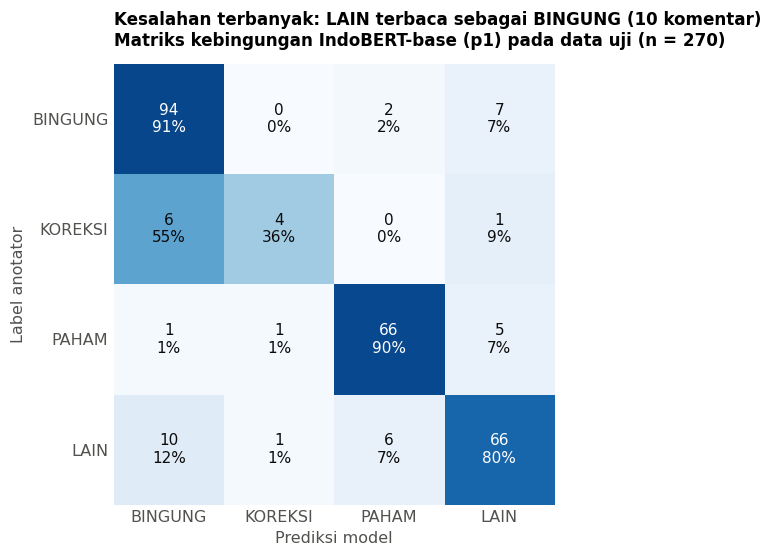

In [ ]:
# Sel 7 · Tabel hasil & matriks kebingungan model utama
tabel_hasil = pd.DataFrame(hasil_model).sort_values("macro_F1_uji", ascending=False)
tabel_hasil.to_csv("hasil/tabel_hasil_model.csv", index=False)
print("Hasil pada data uji (video yang tidak pernah dilihat saat latih) -> hasil/tabel_hasil_model.csv")
display(tabel_hasil)

if model_tr is not None:
    NAMA_UTAMA = nama_tr_terbaik
else:
    NAMA_UTAMA = NAMA_TFIDF_TERBAIK
pred_utama = pred_model_tr if model_tr is not None else prediksi_uji[NAMA_UTAMA]
print(f"\nModel utama: {NAMA_UTAMA}\n")
print(classification_report(y[idx_uji], pred_utama, target_names=LABEL, digits=3, zero_division=0))
if "sumber_label" in data:
    m = data["sumber_label"].to_numpy()[idx_uji] == "manusia_irisan"
    if m.sum() >= 10:
        print(f"Macro-F1 khusus komentar irisan (label konsensus 3 manusia, n={m.sum()}): "
              f"{f1_score(y[idx_uji][m], pred_utama[m], average='macro'):.3f}")

cm = confusion_matrix(y[idx_uji], pred_utama, labels=range(len(LABEL)))
persen = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
salah = [(cm[i, j], LABEL[i], LABEL[j]) for i in range(len(LABEL)) for j in range(len(LABEL)) if i != j]
n_salah, asli, tebak = max(salah)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.imshow(persen, cmap="Blues", vmin=0, vmax=1)
for i in range(len(LABEL)):
    for j in range(len(LABEL)):
        ax.text(j, i, f"{cm[i, j]}\n{persen[i, j]:.0%}", ha="center", va="center", fontsize=10,
                color="white" if persen[i, j] > 0.55 else TINTA)
ax.set_xticks(range(len(LABEL)), LABEL)
ax.set_yticks(range(len(LABEL)), LABEL)
ax.set_xlabel("Prediksi model")
ax.set_ylabel("Label anotator")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"Kesalahan terbanyak: {asli} terbaca sebagai {tebak} ({n_salah} komentar)\n"
             f"Matriks kebingungan {NAMA_UTAMA} pada data uji (n = {len(idx_uji)})", fontsize=11)
simpan_gambar(fig, "gambar_matriks_kebingungan")
plt.show()

In [ ]:
# Sel 8 · Contoh salah klasifikasi
uji = data.iloc[idx_uji].assign(prediksi=[LABEL[i] for i in pred_utama])
keliru = uji[uji["label"] != uji["prediksi"]]
pasangan = keliru.groupby(["label", "prediksi"]).size().sort_values(ascending=False).rename("jumlah").reset_index()
print(f"{len(keliru)} dari {len(uji)} komentar uji salah diklasifikasi. Pasangan terbanyak:")
display(pasangan.head(6))
contoh = keliru.sample(min(25, len(keliru)), random_state=SEED)[["mapel", "teks_bersih", "label", "prediksi"]]
contoh.to_csv("hasil/contoh_salah_klasifikasi.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(contoh.head(12))
print("-> hasil/contoh_salah_klasifikasi.csv")

40 dari 270 komentar uji salah diklasifikasi. Pasangan terbanyak:


,label,prediksi,jumlah
0,LAIN,BINGUNG,10
1,BINGUNG,LAIN,7
2,LAIN,PAHAM,6
3,KOREKSI,BINGUNG,6
4,PAHAM,LAIN,5
5,BINGUNG,PAHAM,2


[Tabel 12 contoh teks komentar dihapus dari versi publik untuk menjaga privasi penonton.
 Berkas lengkapnya ada di hasil/contoh_salah_klasifikasi.csv pada Google Drive tim.]


-> hasil/contoh_salah_klasifikasi.csv


-> hasil/gambar_jenis_kebingungan.png


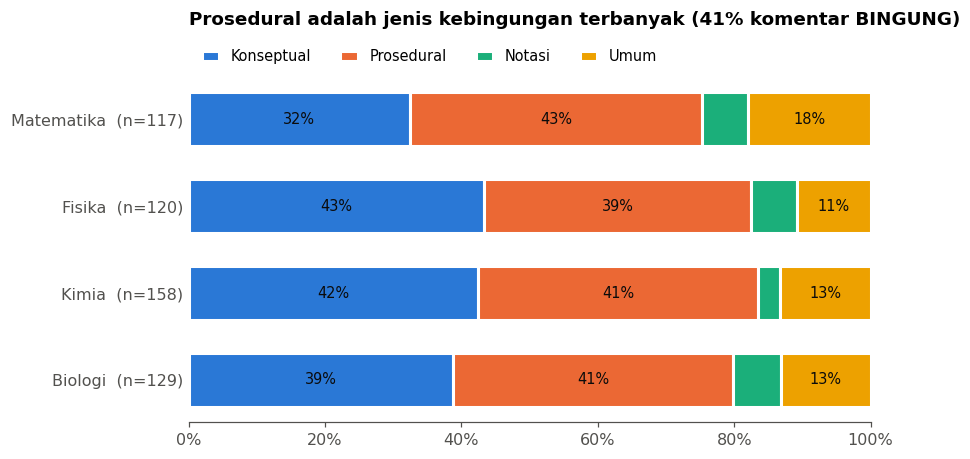

Klasifikasi jenis kebingungan (TF-IDF + LR, CV 5-lipatan per video, n=524): macro-F1 0.463 ± 0.041


In [ ]:
# Sel 9 · Jenis kebingungan per mapel + klasifikasi jenis
bing = data[(data["label"] == "BINGUNG") & data["jenis_bingung"].isin(JENIS)].copy()
porsi = pd.crosstab(bing["mapel"], bing["jenis_bingung"], normalize="index").reindex(columns=JENIS, fill_value=0)
porsi = porsi.reindex([m for m in MAPEL if m in porsi.index])
jumlah = bing["mapel"].value_counts()
pd.crosstab(bing["mapel"], bing["jenis_bingung"], margins=True).to_csv("hasil/tabel_jenis_kebingungan.csv")
dominan = bing["jenis_bingung"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(8, 0.62 * len(porsi) + 1.6))
kiri = np.zeros(len(porsi))
for k, (jenis, warna) in enumerate(zip(JENIS, WARNA)):
    v = porsi[jenis].to_numpy()
    ax.barh(range(len(porsi)), v, left=kiri, color=warna, edgecolor="white", linewidth=2, height=0.62, label=jenis.capitalize())
    for i, (x0, w) in enumerate(zip(kiri, v)):
        if w >= 0.08:
            ax.text(x0 + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9.5, color=TINTA)
    kiri += v
ax.set_yticks(range(len(porsi)), [f"{m}  (n={jumlah.get(m, 0)})" for m in porsi.index])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9.5, handlelength=1.2)
ax.set_title(f"{dominan.index[0].capitalize()} adalah jenis kebingungan terbanyak ({dominan.iloc[0]:.0%} komentar BINGUNG)",
             pad=34)
simpan_gambar(fig, "gambar_jenis_kebingungan")
plt.show()

if bing["video_id"].nunique() >= 5 and bing["jenis_bingung"].value_counts().min() >= 5:
    yj = bing["jenis_bingung"].map(JENIS.index).to_numpy()
    lip = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(bing, yj, bing["video_id"]))
    pipa_j = Pipeline([("fitur", fitur_tfidf()), ("clf", LogisticRegression(C=3, class_weight="balanced", max_iter=3000))])
    s = cross_validate(pipa_j, bing["teks_model"].to_numpy(), yj, cv=lip, scoring="f1_macro")["test_score"]
    print(f"Klasifikasi jenis kebingungan (TF-IDF + LR, CV 5-lipatan per video, n={len(bing)}): "
          f"macro-F1 {s.mean():.3f} ± {s.std():.3f}")

Memetakan 68175 komentar penonton dengan model: IndoBERT-base (p1)
Indeks Kebingungan keseluruhan: 27.3% | per mapel: {'Biologi': '19.8%', 'Fisika': '31.5%', 'Kimia': '27.3%', 'Matematika': '32.3%'}


,mapel,topik,komentar_materi,bingung,indeks_kebingungan,ci_bawah,ci_atas
17,Kimia,hidrolisis garam,626,324,0.517572,0.478440,0.556490
16,Kimia,asam basa ph,894,429,0.479866,0.447272,0.512631
7,Biologi,sistem imun,670,293,0.437313,0.400214,0.475127
29,Matematika,trigonometri sudut berelasi,532,200,0.375940,0.335808,0.417851
26,Matematika,logaritma,3464,1276,0.368360,0.352451,0.384561
15,Fisika,usaha dan energi,686,250,0.364431,0.329264,0.401109
8,Fisika,gelombang mekanik,316,113,0.357595,0.306750,0.411861
13,Fisika,momentum dan impuls,246,87,0.353659,0.296581,0.415237
20,Kimia,konsep mol,986,337,0.341785,0.312844,0.371954
28,Matematika,peluang kejadian,1349,461,0.341735,0.316906,0.367462


-> hasil/gambar_indeks_kebingungan_topik.png


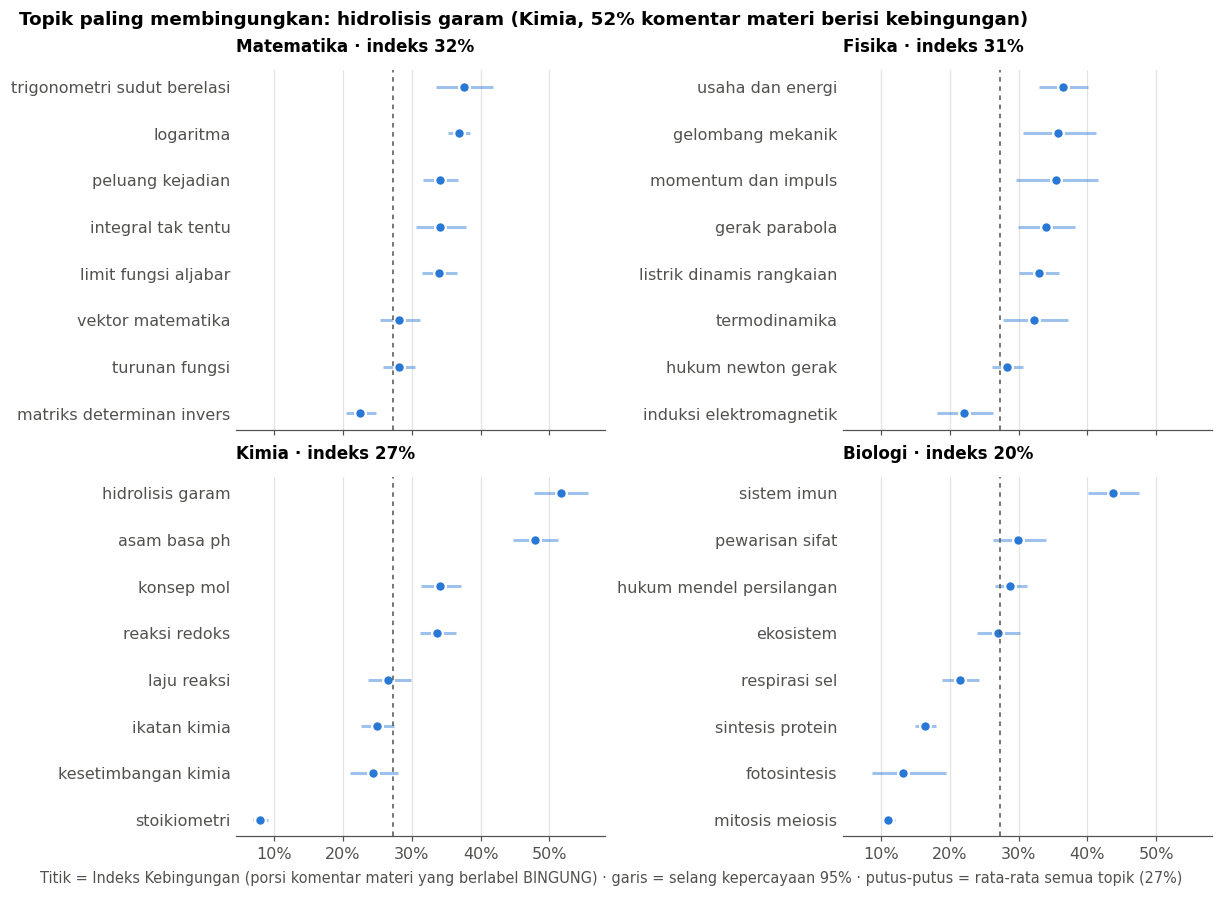

Porsi komentar yang menyebut menit, per label: {'BINGUNG': '7.4%', 'KOREKSI': '13.3%', 'LAIN': '2.7%', 'PAHAM': '0.3%'}
-> hasil/gambar_posisi_kebingungan.png


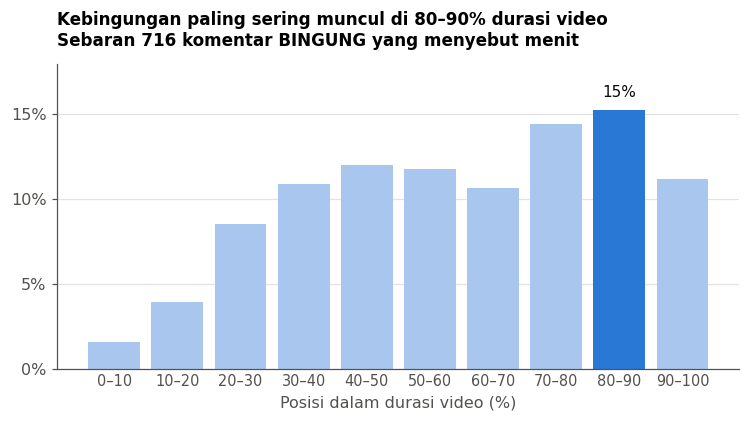

In [ ]:
# Sel 10 · Pemetaan: Indeks Kebingungan per topik & posisi kebingungan dalam video
MIN_KOMENTAR_MATERI = 20     # topik dengan komentar materi lebih sedikit tidak ditampilkan (indeks tidak stabil)

semua = pd.read_csv("data/komentar_bersih.csv", dtype=str).fillna("")
for c in ["hanya_emoji", "spam_duplikat", "dari_kreator"]:
    semua[c] = pd.to_numeric(semua[c], errors="coerce").fillna(0).astype(int) if c in semua else 0
semua = semua[(semua.hanya_emoji == 0) & (semua.spam_duplikat == 0) & (semua.dari_kreator == 0)
              & (semua.teks_bersih.str.len() >= 2)].copy()
semua = semua[~semua["judul"].str.contains("bakteri fotosintesis|PSB", case=False)].copy()
if "topik" not in semua:
    semua["topik"] = ""
semua["topik"] = semua["topik"].where(semua["topik"] != "", semua["judul"])
print(f"Memetakan {len(semua)} komentar penonton dengan model: {NAMA_UTAMA}")
if model_tr is not None:
    pred = prob_teks(model_tr, tok_tr, semua["teks_bersih"].map(bersih_transformer).tolist(), bs=128).argmax(1)
else:
    akhir = pipa_tfidf[NAMA_TFIDF_TERBAIK][0].fit(X, y)          # model TF-IDF dilatih ulang di seluruh data berlabel
    pred = akhir.predict(semua["teks_bersih"].map(bersih_tfidf).to_numpy())
semua["label_peta"] = [LABEL[i] for i in pred]
manusia = dict(zip(data["id_komentar"], data["label"]))         # komentar yang sudah dilabeli manusia memakai label manusia
semua["label_peta"] = [manusia.get(i, p) for i, p in zip(semua["id_komentar"], semua["label_peta"])]


def wilson(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)


materi = semua[semua["label_peta"] != "LAIN"]
ik = materi.groupby(["mapel", "topik"]).agg(komentar_materi=("label_peta", "size"),
                                             bingung=("label_peta", lambda s: int((s == "BINGUNG").sum()))).reset_index()
ik["indeks_kebingungan"] = ik["bingung"] / ik["komentar_materi"]
ci = [wilson(k, n) for k, n in zip(ik["bingung"], ik["komentar_materi"])]
ik["ci_bawah"], ik["ci_atas"] = [c[0] for c in ci], [c[1] for c in ci]
ik = ik.sort_values("indeks_kebingungan", ascending=False)
ik.to_csv("hasil/tabel_indeks_kebingungan_topik.csv", index=False)
ik_mapel = materi.groupby("mapel")["label_peta"].apply(lambda s: (s == "BINGUNG").mean())
ik_total = (materi["label_peta"] == "BINGUNG").mean()
print(f"Indeks Kebingungan keseluruhan: {ik_total:.1%} | per mapel:", {k: f"{v:.1%}" for k, v in ik_mapel.items()})
tampil = ik[ik["komentar_materi"] >= MIN_KOMENTAR_MATERI]
display(tampil.head(10))

mapel_ada = [m for m in MAPEL if m in set(tampil["mapel"])]
if mapel_ada:
    puncak = tampil.iloc[0]
    tinggi = max(len(tampil[tampil.mapel == m]) for m in mapel_ada)
    fig, axes = plt.subplots(2, 2, figsize=(11, 0.34 * tinggi * 2 + 2.6), sharex=True, layout="constrained")
    for ax, m in zip(axes.flat, MAPEL):
        sub = tampil[tampil["mapel"] == m].sort_values("indeks_kebingungan")
        if sub.empty:
            ax.set_visible(False)
            continue
        pos = np.arange(len(sub))
        ax.hlines(pos, sub["ci_bawah"], sub["ci_atas"], color=BIRU, linewidth=2, alpha=0.45)
        ax.plot(sub["indeks_kebingungan"], pos, "o", color=BIRU, markersize=7, markeredgecolor="white", markeredgewidth=1.5)
        ax.axvline(ik_total, color=TINTA2, linestyle=(0, (3, 3)), linewidth=1)
        ax.set_yticks(pos, [t[:28] for t in sub["topik"]])
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.grid(axis="x")
        ax.set_axisbelow(True)
        ax.set_title(f"{m} · indeks {ik_mapel.get(m, 0):.0%}", fontsize=11)
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    fig.suptitle(f"Topik paling membingungkan: {puncak.topik} ({puncak.mapel}, {puncak.indeks_kebingungan:.0%} komentar "
                 f"materi berisi kebingungan)", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(f"Titik = Indeks Kebingungan (porsi komentar materi yang berlabel BINGUNG) · garis = selang kepercayaan 95% · "
                  f"putus-putus = rata-rata semua topik ({ik_total:.0%})", fontsize=9.5, color=TINTA2)
    simpan_gambar(fig, "gambar_indeks_kebingungan_topik")
    plt.show()

# posisi kebingungan dalam video (dari komentar yang menyebut menit)
semua["posisi_relatif"] = pd.to_numeric(semua["posisi_relatif"], errors="coerce") if "posisi_relatif" in semua else np.nan
ts = semua[semua["posisi_relatif"].between(0, 1)]
ts_b = ts[ts["label_peta"] == "BINGUNG"]
punya_ts = semua.assign(ada=semua["posisi_relatif"].notna()).groupby("label_peta")["ada"].mean()
print("Porsi komentar yang menyebut menit, per label:", {k: f"{v:.1%}" for k, v in punya_ts.items()})
if len(ts_b) >= 20:
    hit, tepi = np.histogram(ts_b["posisi_relatif"], bins=10, range=(0, 1))
    porsi_bin = hit / hit.sum()
    k = int(porsi_bin.argmax())
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.bar(np.arange(10), porsi_bin, width=0.82, color=[BIRU if i == k else "#a9c7ee" for i in range(10)])
    ax.text(k, porsi_bin[k] + 0.006, f"{porsi_bin[k]:.0%}", ha="center", va="bottom", fontsize=10, color=TINTA)
    ax.set_xticks(np.arange(10), [f"{i * 10}–{i * 10 + 10}" for i in range(10)], fontsize=9.5)
    ax.set_xlabel("Posisi dalam durasi video (%)")
    ax.set_ylim(0, porsi_bin.max() * 1.18)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(0.05))
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=0)
    ax.set_title(f"Kebingungan paling sering muncul di {k * 10}–{k * 10 + 10}% durasi video\n"
                 f"Sebaran {len(ts_b)} komentar BINGUNG yang menyebut menit", fontsize=11)
    simpan_gambar(fig, "gambar_posisi_kebingungan")
    plt.show()
else:
    k = None
    print("Komentar BINGUNG bertimestamp terlalu sedikit untuk grafik posisi.")

In [ ]:
# Sel 11 · Ringkasan angka hasil
baris_utama = tabel_hasil.set_index("model").loc[NAMA_UTAMA]
baris_tfidf = tabel_hasil.set_index("model").loc[NAMA_TFIDF_TERBAIK]
ringkas = [
    "RINGKASAN BINGUNG-ID",
    f"Dataset: {len(data)} komentar berlabel dari {data['video_id'].nunique()} video; "
    + ", ".join(f"{l} {int((data['label'] == l).sum())}" for l in LABEL),
    f"Pembagian data per video: latih {len(idx_latih)}, validasi {len(idx_val)}, uji {len(idx_uji)} komentar",
    f"Model utama: {NAMA_UTAMA} · macro-F1 uji {baris_utama['macro_F1_uji']:.3f} ({baris_utama['keterangan']}) · "
    f"akurasi {baris_utama['akurasi_uji']:.3f}",
    f"TF-IDF terbaik: {NAMA_TFIDF_TERBAIK} · macro-F1 uji {baris_tfidf['macro_F1_uji']:.3f} ({baris_tfidf['keterangan']})",
    f"F1 per kelas (model utama): " + ", ".join(f"{l} {baris_utama['F1_' + l]:.3f}" for l in LABEL),
    f"Kesalahan terbanyak: {asli} terbaca sebagai {tebak} ({n_salah} komentar uji)",
    f"Jenis kebingungan terbanyak: {dominan.index[0]} ({dominan.iloc[0]:.0%}); "
    + ", ".join(f"{j} {v:.0%}" for j, v in dominan.items()),
    f"Pemetaan: {len(semua)} komentar; Indeks Kebingungan keseluruhan {ik_total:.1%}; per mapel "
    + ", ".join(f"{m} {v:.1%}" for m, v in ik_mapel.items()),
    "5 topik paling membingungkan (min. %d komentar materi): " % MIN_KOMENTAR_MATERI
    + "; ".join(f"{r.topik} ({r.mapel}) {r.indeks_kebingungan:.0%}" for r in tampil.head(5).itertuples()),
]
if k is not None:
    ringkas.append(f"Posisi kebingungan terbanyak: {k * 10}–{k * 10 + 10}% durasi video (n={len(ts_b)})")
open("hasil/ringkasan_untuk_makalah.txt", "w", encoding="utf-8").write("\n".join(ringkas))
print("\n".join(ringkas))
print("\n-> hasil/ringkasan_untuk_makalah.txt")

RINGKASAN BINGUNG-ID
Dataset: 1498 komentar berlabel dari 241 video; BINGUNG 527, KOREKSI 56, PAHAM 393, LAIN 522
Pembagian data per video: latih 1066, validasi 162, uji 270 komentar
Model utama: IndoBERT-base (p1) · macro-F1 uji 0.774 (rata-rata 3 benih: 0.774 ± 0.010) · akurasi 0.826
TF-IDF terbaik: TF-IDF + Regresi Logistik · macro-F1 uji 0.732 (CV 5-lipatan per video: 0.724 ± 0.017)
F1 per kelas (model utama): BINGUNG 0.864, KOREKSI 0.588, PAHAM 0.865, LAIN 0.761
Kesalahan terbanyak: LAIN terbaca sebagai BINGUNG (10 komentar uji)
Jenis kebingungan terbanyak: PROSEDURAL (41%); PROSEDURAL 41%, KONSEPTUAL 40%, UMUM 14%, NOTASI 6%
Pemetaan: 68175 komentar; Indeks Kebingungan keseluruhan 27.3%; per mapel Biologi 19.8%, Fisika 31.5%, Kimia 27.3%, Matematika 32.3%
5 topik paling membingungkan (min. 20 komentar materi): hidrolisis garam (Kimia) 52%; asam basa ph (Kimia) 48%; sistem imun (Biologi) 44%; trigonometri sudut berelasi (Matematika) 38%; logaritma (Matematika) 37%
Posisi kebingung

In [ ]:
# Sel 12 · Simpan model + fungsi prediksi CSV (untuk babak final / leaderboard)
import joblib
SIMPAN_TRANSFORMER = True          # ±500 MB di Drive; ubah ke False bila ruang Drive sempit
akhir_tfidf = pipa_tfidf[NAMA_TFIDF_TERBAIK][0].fit(X, y)
joblib.dump(akhir_tfidf, "hasil/model_tfidf.joblib")
print("-> hasil/model_tfidf.joblib")
if model_tr is not None and SIMPAN_TRANSFORMER:
    model_tr.save_pretrained("hasil/model_transformer")
    tok_tr.save_pretrained("hasil/model_transformer")
    print("-> hasil/model_transformer/")


def prediksi_csv(path_masuk, kolom_teks="teks", path_keluar="hasil/prediksi.csv"):
    df = pd.read_csv(path_masuk, dtype=str).fillna("")
    teks = df[kolom_teks].tolist()
    if model_tr is not None:
        df["prediksi"] = [LABEL[i] for i in prob_teks(model_tr, tok_tr, [bersih_transformer(t) for t in teks]).argmax(1)]
    else:
        df["prediksi"] = [LABEL[i] for i in akhir_tfidf.predict([bersih_tfidf(t) for t in teks])]
    df.to_csv(path_keluar, index=False, encoding="utf-8-sig")
    print(f"{len(df)} baris -> {path_keluar}")
    return df

# Contoh: prediksi_csv("data_uji_panitia.csv", kolom_teks="text")

-> hasil/model_tfidf.joblib


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

-> hasil/model_transformer/


In [ ]:
import pandas as pd
print(open("hasil/ringkasan_untuk_makalah.txt", encoding="utf-8").read())
print("\n" + pd.read_csv("hasil/tabel_hasil_model.csv").to_string(index=False))
print("\n" + pd.read_csv("hasil/tabel_pembagian_data.csv").to_string(index=False))

RINGKASAN BINGUNG-ID
Dataset: 1498 komentar berlabel dari 241 video; BINGUNG 527, KOREKSI 56, PAHAM 393, LAIN 522
Pembagian data per video: latih 1066, validasi 162, uji 270 komentar
Model utama: IndoBERT-base (p1) · macro-F1 uji 0.774 (rata-rata 3 benih: 0.774 ± 0.010) · akurasi 0.826
TF-IDF terbaik: TF-IDF + Regresi Logistik · macro-F1 uji 0.732 (CV 5-lipatan per video: 0.724 ± 0.017)
F1 per kelas (model utama): BINGUNG 0.864, KOREKSI 0.588, PAHAM 0.865, LAIN 0.761
Kesalahan terbanyak: LAIN terbaca sebagai BINGUNG (10 komentar uji)
Jenis kebingungan terbanyak: PROSEDURAL (41%); PROSEDURAL 41%, KONSEPTUAL 40%, UMUM 14%, NOTASI 6%
Pemetaan: 68175 komentar; Indeks Kebingungan keseluruhan 27.3%; per mapel Biologi 19.8%, Fisika 31.5%, Kimia 27.3%, Matematika 32.3%
5 topik paling membingungkan (min. 20 komentar materi): hidrolisis garam (Kimia) 52%; asam basa ph (Kimia) 48%; sistem imun (Biologi) 44%; trigonometri sudut berelasi (Matematika) 38%; logaritma (Matematika) 37%
Posisi kebingung

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/DIMAS_TI_2026
import pandas as pd
k = pd.read_csv("data/komentar_bersih.csv", dtype=str).fillna("")
for c in ["hanya_emoji", "spam_duplikat", "dari_kreator"]:
    k[c] = pd.to_numeric(k[c], errors="coerce").fillna(0).astype(int)
layak = k[(k.hanya_emoji == 0) & (k.spam_duplikat == 0) & (k.dari_kreator == 0)]
print("[N] video yang komentarnya diambil:", k["video_id"].nunique())
print("[jumlah] komentar penonton layak dianalisis:", len(layak))

Mounted at /content/drive
/content/drive/MyDrive/DIMAS_TI_2026
[N] video yang komentarnya diambil: 278
[jumlah] komentar penonton layak dianalisis: 70829
